# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [47]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [48]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [49]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [50]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [51]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [52]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [53]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [54]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [55]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [56]:
# cantidad de nulos para users
print(users.isna().sum())
print("---------------------")
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
---------------------
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [57]:
# cantidad de nulos para usage
print(usage.isna().sum())
print("---------------------")
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
---------------------
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico de valores nulos:**

* **`users['city']` (11.73% nulos / 469 registros):** Proporción moderada; se recomienda dejarlos como nulos o etiquetarlos como "Desconocida" para no perder información demográfica de esos usuarios.

* **`users['churn_date']` (88.35% nulos / 3,534 registros):** Aunque supera el 80%, se conserva intacta porque los nulos representan clientes que siguen activos en ConnectaTel.

* **`usage['date']` (0.13% nulos / 50 registros):** Proporción mínima (menor al 5%); se mantienen como nulos sin afectar el volumen general del análisis.

* **`usage['duration']` (55.19%) y `usage['length']` (44.74%):** Se dejan como nulos porque son estructurales (las llamadas no tienen longitud de texto y los mensajes no tienen duración en minutos).

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [58]:
# explorar columnas numéricas de users

In [59]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000



- La columna `user_id` contiene identificadores únicos correlativos (del 10000 al 13999) sin valores atípicos ni anomalías.
- La columna `age` presenta un valor mínimo de `-999`, el cual corresponde a un valor sentinel/inválido que debe ser tratado antes del análisis estadístico.

In [60]:
# explorar columnas numéricas de usage

In [61]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` funcionan correctamente como identificadores numéricos sin rangos anómalos.
- Las columnas `duration` y `length` muestran valores mínimos positivos y rangos coherentes con la duración de llamadas y longitud de mensajes, sin presencia de códigos de error negativos.

In [62]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"--- Valores únicos en {col} ---")
    print(users[col].value_counts(dropna=False))
    print()

--- Valores únicos en city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- Valores únicos en plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` contiene el carácter `'?'` como valor inválido/sentinel representando ciudades desconocidas, además de los valores nulos detectados anteriormente.
- La columna `plan` únicamente registra las dos categorías válidas esperadas (`Basico` y `Premium`), sin errores de escritura ni sentinels.

In [63]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` contiene exclusivamente las dos categorías válidas del servicio (`call` y `text`), sin valores inválidos ni inconsistencias.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  

¿En qué columnas encontraste valores inválidos o sentinels?

- En `users['age']` se encontró el valor numérico `-999` (edad imposible).
- En `users['city']` se encontró el carácter `'?'` como marcador de ciudad desconocida.

¿Qué acción tomarías?

- En `users['age']`, reemplazar `-999` con la mediana de edad para no distorsionar los cálculos estadísticos ni perder los registros de esos usuarios.
- En `users['city']`, reemplazar `'?'` por `pd.NA` para estandarizar todos los datos faltantes de ubicación bajo un mismo formato nulo.



### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [64]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
print(users['reg_date'].dtype)
print("Nulos en reg_date:", users['reg_date'].isna().sum())

datetime64[ns]
Nulos en reg_date: 0


In [65]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
print(usage['date'].dtype)
print("Nulos en date:", usage['date'].isna().sum())

datetime64[ns]
Nulos en date: 50


In [66]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


- En `reg_date`, los registros se distribuyen en `2022` (1,314), `2023` (1,316) y `2024` (1,330), pero aparecen **40 fechas futuras en `2026`** que están fuera del límite del dataset (`2024`) y deberán marcarse como nulas en la limpieza.

In [67]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())

2024.0    39950
NaN          50
Name: date, dtype: int64


- En `date`, los **39,950 registros** con fecha pertenecen al año `2024` y hay **50 valores `NaN`** sin fecha válida. Basaremos el análisis temporal en los registros válidos dentro de este periodo. 

Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  

¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

- Sí: en `users['reg_date']` aparecen **40 registros** con el año `2026`, lo cual es una fecha futura respecto al corte del dataset (hasta `2024`). Los años `2022` (1,314), `2023` (1,316) y `2024` (1,330) están dentro del periodo válido.
- En `usage['date']`, los **39,950 registros** con fecha válida corresponden al año `2024`, y hay **50 registros `NaN`** (sin fecha o con formato inválido tras `pd.to_datetime(..., errors='coerce')`).
  
 ¿Qué harías con ellas?

- Reemplazar las fechas con año `2026` en `users['reg_date']` por `pd.NA` (`NaT`) en el paso de limpieza para evitar sesgos temporales en el análisis.
- Mantener como nulos (`NaT`) los **50 registros faltantes** en `usage['date']` (representan solo el 0.13% del total de 40,000 filas) y filtrar el análisis temporal estrictamente al periodo válido hasta `2024`.

 

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [68]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
print("Mediana usada:", age_mediana)
users['age'].describe()

Mediana usada: 48.0


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [69]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [70]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = users['reg_date'].mask(users['reg_date'].dt.year > 2024, pd.NaT)

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [71]:
# Verificación MAR en usage (Missing At Random) para duration
print("Nulos de duration según type:")
print(usage.groupby('type', dropna=False)['duration'].apply(lambda s: s.isna().sum()))
print("\nProporción de nulos de duration según type:")
print(usage.groupby('type', dropna=False)['duration'].apply(lambda s: s.isna().mean()))

Nulos de duration según type:
type
call        0
text    22076
Name: duration, dtype: int64

Proporción de nulos de duration según type:
type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [72]:
# Verificación MAR en usage (Missing At Random) para length
print("Nulos de length según type:")
print(usage.groupby('type', dropna=False)['length'].apply(lambda s: s.isna().sum()))
print("\nProporción de nulos de length según type:")
print(usage.groupby('type', dropna=False)['length'].apply(lambda s: s.isna().mean()))

Nulos de length según type:
type
call    17896
text        0
Name: length, dtype: int64

Proporción de nulos de length según type:
type
call    0.99933
text    0.00000
Name: length, dtype: float64


✍️ **Diagnóstico de valores nulos en `duration` y `length` (MAR)**:

**¿Son MAR (Missing At Random) respecto a `type`?**
  
  - Sí: la falta de datos depende directamente del tipo de evento registrado en `type`:
    - En `duration`, hay **0 nulos** en `call` (`0.0%`) y **22,076 nulos** en `text` (`99.93%`).
    - En `length`, hay **17,896 nulos** en `call` (`99.93%`) y **0 nulos** en `text` (`0.0%`).

**¿Qué acción se toma y por qué?**
  
  - Se **mantienen como nulos (`NaN`)** y no se imputan con ceros ni promedios artificiales, ya que las llamadas no tienen longitud de mensaje y los mensajes de texto no tienen duración en minutos; imputarlos sesgaría las métricas reales de consumo.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [73]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id", as_index=False)
    .agg(
        total_mensajes=("is_text", "sum"),
        total_llamadas=("is_call", "sum"),
        total_minutos=("duration", "sum")
    )
)

# observar resultado
usage_agg.head(3)

,user_id,total_mensajes,total_llamadas,total_minutos
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [74]:
# Renombrar columnas
usage_agg = usage_agg.rename(
    columns={
        "total_mensajes": "cant_mensajes",
        "total_llamadas": "cant_llamadas",
        "total_minutos": "cant_minutos_llamada"
    }
)

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [75]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Los usuarios sin registros en usage no tienen consumo: se rellenan con 0
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [76]:
# Resumen estadístico de las columnas numéricas
user_profile[["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [77]:
# Distribución porcentual del tipo de plan
print("Conteo por plan:")
print(user_profile["plan"].value_counts(dropna=False))

print("\nPorcentaje por plan:")
print((user_profile["plan"].value_counts(normalize=True, dropna=False) * 100).round(2))

Conteo por plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64

Porcentaje por plan:
Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

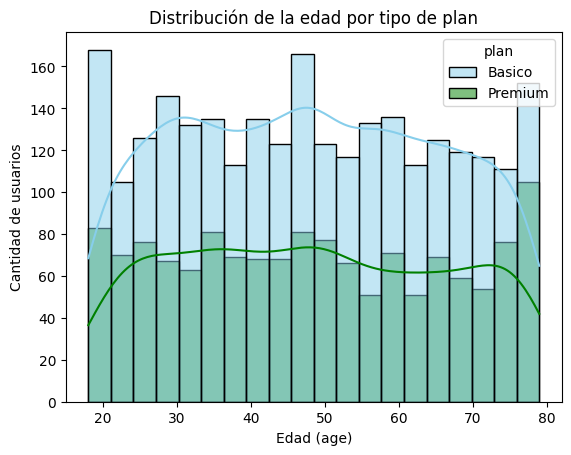

In [78]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, bins=20)
plt.title('Distribución de la edad por tipo de plan')
plt.xlabel('Edad (age)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- **Tipo de distribución:** Aproximadamente uniforme (plana) entre los 18 y 79 años, sin sesgos marcados hacia edades jóvenes o mayores (con un ligero pico alrededor de los 48 años producto de la imputación de la mediana).
- **Comparación por plan:** No existe un patrón de edad que diferencie a los clientes de `Basico` y `Premium`; ambos planes presentan una distribución muy similar a lo largo de todos los rangos de edad, variando únicamente en volumen total debido a que el plan `Basico` concentra cerca del 65% de los usuarios.

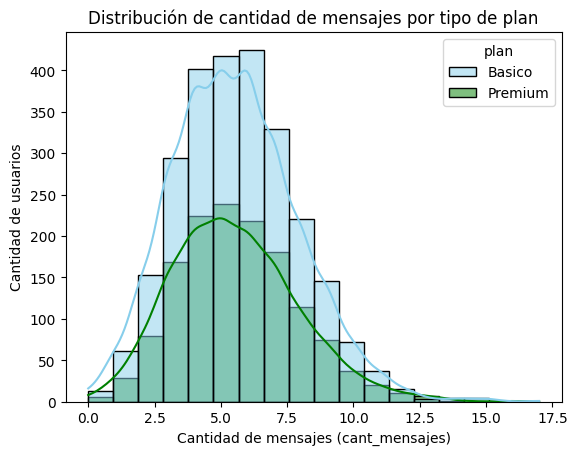

In [79]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True, bins=18)
plt.title('Distribución de cantidad de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes (cant_mensajes)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- **Tipo de distribución:** Ligeramente sesgada a la derecha (asimetría positiva), con la mayor concentración de usuarios enviando entre 4 y 7 mensajes (mediana de 5 mensajes) y una cola corta hacia valores altos (hasta 17 mensajes).
- **Comparación por plan:** No se observa una diferencia significativa en el comportamiento de envío de mensajes según el plan; tanto los usuarios `Basico` como `Premium` mantienen un patrón de consumo casi idéntico en proporción.

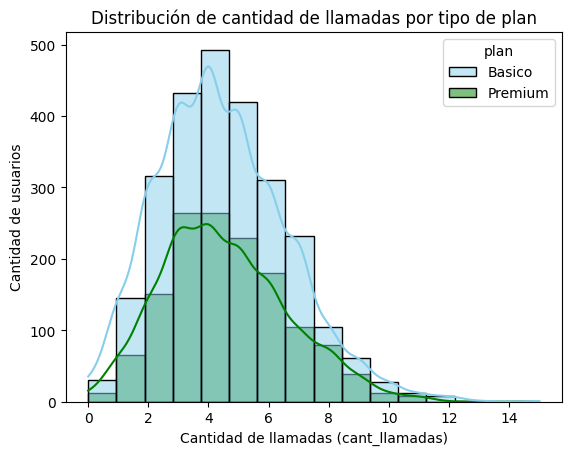

In [80]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True, bins=16)
plt.title('Distribución de cantidad de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas (cant_llamadas)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- **Tipo de distribución:** Moderadamente sesgada a la derecha (asimetría positiva), concentrándose principalmente entre 3 y 6 llamadas por usuario (mediana de 4 llamadas) y extendiéndose hasta un máximo de 15 llamadas.
- **Comparación por plan:** Ambos planes muestran una curva de comportamiento prácticamente paralela; tener plan `Premium` no implica realizar más llamadas que los usuarios del plan `Basico`.

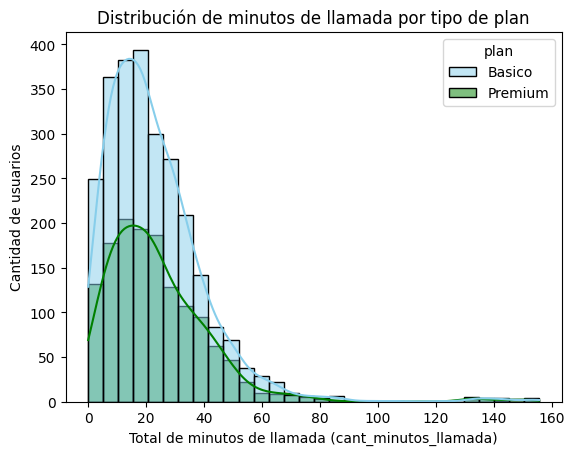

In [81]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True, bins=30)
plt.title('Distribución de minutos de llamada por tipo de plan')
plt.xlabel('Total de minutos de llamada (cant_minutos_llamada)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- **Tipo de distribución:** Marcadamente sesgada a la derecha (asimetría positiva pronunciada), donde la mayoría de los clientes acumulan entre 10 y 35 minutos totales (mediana de ~19.78 min), pero existe una cola larga de usuarios intensivos que llegan hasta ~155.69 minutos.
- **Comparación por plan:** La forma de la distribución es muy similar entre `Basico` y `Premium`, lo que confirma que el nivel de consumo de minutos no está determinado por el tipo de plan contratado actualmente.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

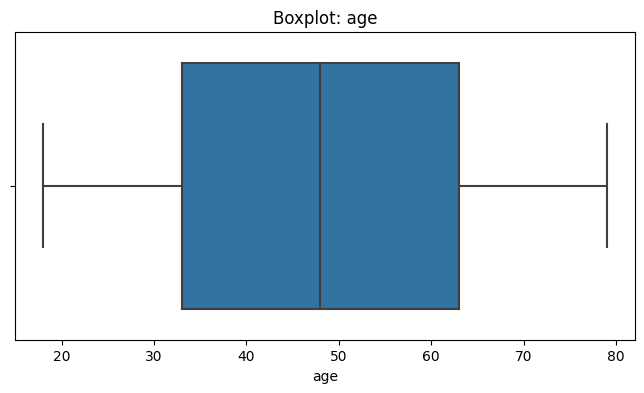

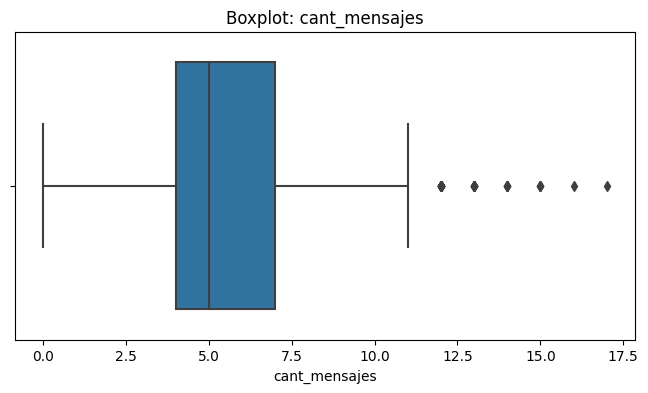

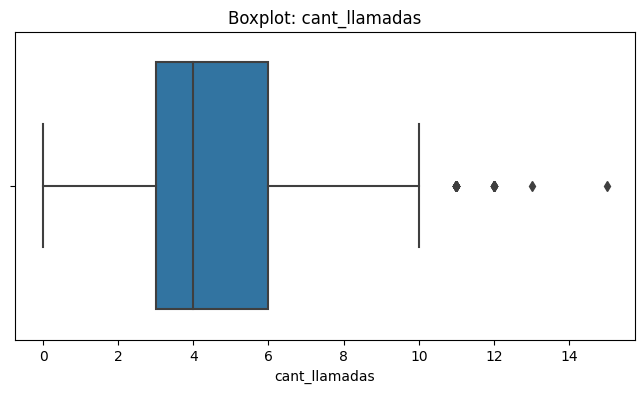

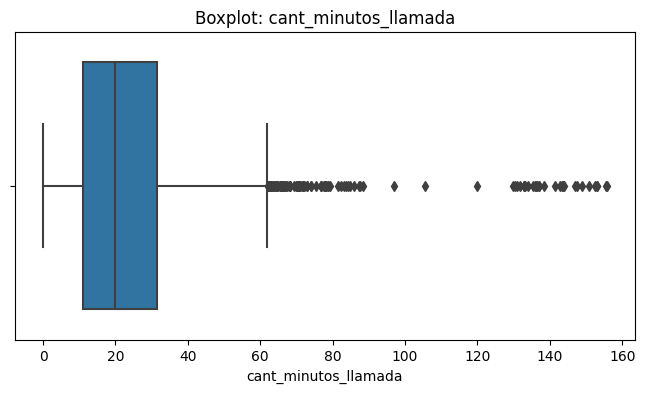

In [82]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- Age: no presenta outliers (todos los valores se encuentran dentro del rango válido de 18 a 79 años tras reemplazar `-999`).
- cant_mensajes: sí presenta outliers en el extremo superior (valores atípicos por encima del bigote superior, a partir de 12 mensajes hasta un máximo de 17).
- cant_llamadas: sí presenta outliers en el extremo superior (valores atípicos por encima del bigote superior, a partir de 11 llamadas hasta un máximo de 15).
- cant_minutos_llamada: sí presenta varios outliers en el extremo superior con una cola larga hacia la derecha (a partir de ~61.86 minutos hasta un máximo de ~155.69 minutos).

In [83]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, Límite superior={limite_superior:.2f}, Outliers={n_outliers}")



cant_mensajes: Q1=4.00, Q3=7.00, IQR=3.00, Límite superior=11.50, Outliers=46
cant_llamadas: Q1=3.00, Q3=6.00, IQR=3.00, Límite superior=10.50, Outliers=30
cant_minutos_llamada: Q1=11.11, Q3=31.41, IQR=20.30, Límite superior=61.87, Outliers=109


In [84]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: mantener outliers, porque representan usuarios con mayor actividad real de mensajería (hasta 17 mensajes) y no corresponden a errores de captura.
- cant_llamadas: mantener outliers, porque reflejan clientes que realizan más llamadas de forma legítima (hasta 15 llamadas) dentro del comportamiento esperado del servicio.
- cant_minutos_llamada: mantener outliers, porque identifican a los usuarios de consumo intensivo de voz (hasta ~155.69 minutos), quienes son clave para detectar oportunidades de migración de plan o venta adicional.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [85]:
# Crear columna grupo_uso
import numpy as np

# Definir condiciones lógicas
condiciones_uso = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

# Definir etiquetas correspondientes
categorias_uso = ['Bajo uso', 'Uso medio']

# Crear columna grupo_uso
user_profile['grupo_uso'] = np.select(condiciones_uso, categorias_uso, default='Alto uso')

In [86]:
# verificar cambios
print(user_profile['grupo_uso'].value_counts(dropna=False))
user_profile.head()

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [87]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

categorias_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, categorias_edad, default='Adulto Mayor')

In [88]:
# verificar cambios
# verificar cambios
print(user_profile['grupo_edad'].value_counts(dropna=False))
user_profile[['user_id', 'age', 'plan', 'grupo_uso', 'grupo_edad']].head()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


,user_id,age,plan,grupo_uso,grupo_edad
0,10000,38.0,Basico,Uso medio,Adulto
1,10001,53.0,Basico,Alto uso,Adulto
2,10002,57.0,Basico,Uso medio,Adulto
3,10003,69.0,Premium,Alto uso,Adulto Mayor
4,10004,63.0,Basico,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

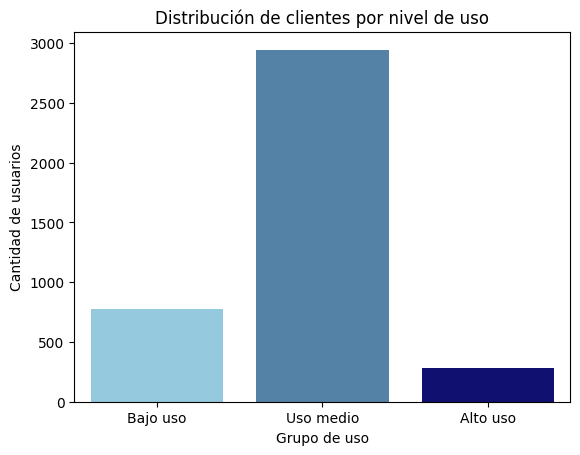

In [89]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    palette=['skyblue', 'steelblue', 'navy']
)
plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

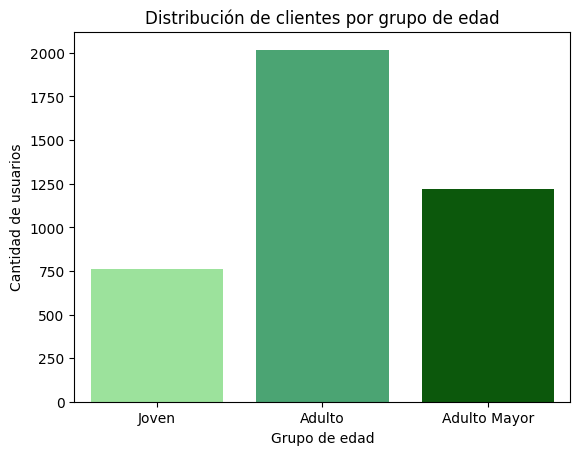

In [90]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    palette=['lightgreen', 'mediumseagreen', 'darkgreen']
)
plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- **`users['age']` (sentinel `-999`):** Se detectaron edades imposibles registradas como `-999` (lo que distorsionaba la media inicial a `33.74` años); se reemplazaron con la mediana (`48.0` años), estabilizando el rango válido entre `18` y `79` años.
- **`users['city']` (`565` registros faltantes / `14.13%`):** Originalmente contenía `469` valores nulos (`11.73%`) más `96` registros con el carácter inválido `'?'` (`2.40%`), los cuales se estandarizaron como `NaN` para evitar sesgos geográficos.
- **`users['reg_date']` (`40` registros / `1.00%`):** Presentaba 40 fechas futuras correspondientes al año `2026` (fuera del corte válido hasta `2024`), que fueron marcadas como `NaT`.
- **`users['churn_date']` (`3,534` nulos / `88.35%`):** Se mantuvieron intactos porque representan usuarios que permanecen activos en ConnectaTel.
- **`usage['date']` (`50` nulos / `0.13%`) y nulos estructurales (MAR):** Los 50 registros sin fecha en `usage` se conservaron como `NaT` por su impacto mínimo, mientras que los nulos en `duration` (`22,076` filas / `55.19%`) y `length` (`17,896` filas / `44.74%`) se confirmaron como *Missing At Random* (MAR) según `type` (`call` vs `text`) y no se imputaron para no sesgar las métricas de uso.


🔍 **Segmentos por Edad**

- **Adulto (`30 a 59 años`):** Es el segmento mayoritario con **2,018 usuarios (`50.45%`)**, representando más de la mitad de la cartera total de ConnectaTel.
- **Adulto Mayor (`60 años o más`):** Es el segundo grupo más relevante con **1,222 usuarios (`30.55%`)**.
- **Joven (`menores de 30 años`):** Representa el grupo más pequeño con **760 usuarios (`19.00%`)**.
- La distribución de edad es uniforme entre `18` y `79` años y se comporta prácticamente igual tanto en el plan `Basico` (`64.88%` de los usuarios) como en el `Premium` (`35.12%`), por lo que la edad no determina actualmente la elección del plan.


📊 **Segmentos por Nivel de Uso**

- **Uso medio:** Concentra la gran mayoría de la base con **2,943 usuarios (`73.58%`)** (quienes realizan entre 5 y 9 llamadas o mensajes sin entrar en bajo uso).
- **Bajo uso:** Agrupa a **778 usuarios (`19.45%`)** que registran menos de 5 llamadas y menos de 5 mensajes.
- **Alto uso:** Corresponde a **279 usuarios (`6.98%`)** que alcanzan 10 o más llamadas o mensajes.
- **Patrones de uso extremo (outliers):** Se identificaron valores atípicos superiores legítimos en `cant_mensajes` (`46` outliers por encima de `11.50`, hasta `17` mensajes), `cant_llamadas` (`30` outliers por encima de `10.50`, hasta `15` llamadas) y especialmente en `cant_minutos_llamada` (`109` outliers por encima de `61.86` min, alcanzando hasta `155.69` minutos). Además, la forma de consumo entre planes `Basico` y `Premium` es casi idéntica.


➡️ Esto sugiere que **los segmentos más valiosos para ConnectaTel son el grupo de `Uso medio` (`73.58%`) y `Adultos` (`50.45%`)** —que representan el núcleo estable de ingresos recurrentes—, junto con **los `279` usuarios de `Alto uso` y los `109` usuarios con consumo intensivo de minutos (hasta `155.69` min)**, quienes generan mayor demanda y excedentes; además, confirma que hoy existe una desconexión entre el plan contratado (`Basico` vs. `Premium`) y el consumo real de los clientes.

💡 **Recomendaciones**

- **Campaña de migración (*upselling*) dirigida a clientes `Basico` de consumo intensivo:** Identificar a los clientes del plan `Basico` que se encuentran entre los outliers de minutos (por encima de ~`62` min) y ofrecerles el plan `Premium`, que incluye `600` minutos y cobra el minuto extra a `$0.07 USD` frente a `$0.10 USD` del `Basico`, por `$13 USD` más al mes.
- **Evaluar un plan intermedio ("ConnectaTel Plus"):** Dado que el **73.58%** de los usuarios está en `Uso medio` y existe un salto grande de precio entre `Basico` (`$12 USD`) y `Premium` (`$25 USD`), conviene considerar una opción intermedia. Como la mediana de consumo es de ~`19.8` minutos y el 75% de los clientes usa menos de ~`31`, la cantidad de minutos incluidos debería definirse con un análisis de consumo más detallado.
- **Paquetes enfocados en datos para `Bajo uso` y `Jóvenes`:** Diseñar beneficios centrados en navegación móvil (`GB`) o redes sociales para atraer al segmento `Joven` (el menos representado, con `19.00%`) y fidelizar a los usuarios `Premium` de bajo consumo.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

https://github.com/juanjo807/telecom-analysis